Começando nessa lição, vou usar o material do livro 
"Probabilidade - um curso introdutório", da edusp

In [3]:
import numpy as np 
from math import factorial
import matplotlib.pyplot as plt


(array([0.002, 0.011, 0.016, 0.043, 0.063, 0.08 , 0.119, 0.113, 0.145,
        0.12 , 0.088, 0.069, 0.054, 0.033, 0.016, 0.01 , 0.008, 0.004,
        0.004, 0.002]),
 array([ 2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13., 14.,
        15., 16., 17., 18., 19., 20., 21., 22.]),
 <BarContainer object of 20 artists>)

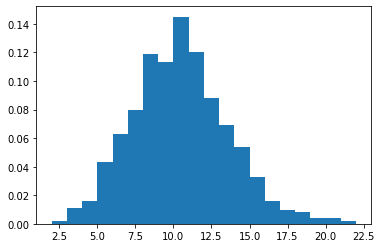

In [4]:
# Distribuição de poisson:
# Quando o número de ensaios de Bernoulli tende a infinito
# ex: chance de 1 em um milhão; você tenta 10 milhões; média de sucesso é 10 (desvio padrão: raiz de 10)

lam = 10
np_p = np.random.poisson(lam = lam, size = 1000)
plt.hist(np_p, density = True, bins = 20)


<BarContainer object of 20 artists>

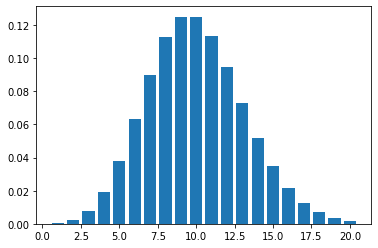

In [5]:
# Livro: pág. 146

def poisson(lam, k): 
    """Given average lam of event, chance of event occuring k times"""
    return np.exp(-lam)*(lam**k)/factorial(k)

formula_p = [poisson(lam, k) for k in range(1,21)]

plt.bar(range(1,21), formula_p)


In [6]:
lala = list(range(10))
np.random.shuffle(lala)
lala

[8, 6, 1, 7, 2, 9, 5, 4, 0, 3]

5998.4 29996.0 -10000.0 5 {-10000.0: 2, -1.0: 4, 9998.0: 1, 19997.0: 2, 29996.0: 1}


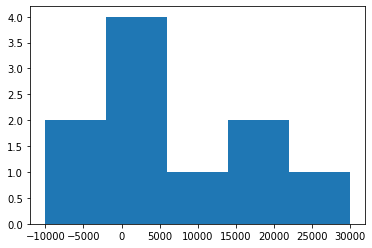

In [61]:
# Using simulation for decision-making

# chances of winning the lottery:
grand_prize = 10_000
num_tickets = 10_000
lottery_ticket_cost = 1


chances_of_winning = 1/num_tickets

gains = [-lottery_ticket_cost, grand_prize-lottery_ticket_cost - lottery_ticket_cost]
probability = [1-chances_of_winning, chances_of_winning]

n = 10
results = np.zeros(n)
for x in range(n):
    result = np.random.choice(a = gains, p = probability, replace = True, size = 10_000)
    results[x] = np.sum(result)
    
print(np.mean(results), np.max(results), np.min(results), len(set(results)), {z:np.sum(results == z) for z in sorted(set(results))})
plt.hist(results, bins = len(set(results)) )
plt.show()

In [65]:
# coincidence

import numpy as np 

deck_13 = np.arange(1,14)
shuffle_deck_13 = np.arange(1,14)
np.random.shuffle(shuffle_deck_13)
deck_13, shuffle_deck_13, (deck_13 == shuffle_deck_13).any()

(array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13]),
 array([10,  6,  1,  5,  8, 13,  9,  3, 11,  2,  4,  7, 12]),
 False)

In [2]:
# Contitional probability
# P(A|B) = P(A&B)/P(B) - chance of A occurring given that B has already occurred
# it reads 'Probability of A given B'
# it means 'Probability of A and B given that B occurred'

# (do livro) ex:
# lança-se um dado duas vezes. 
# P(A) - Qual a chance de se tirar o valor 4? 
# -> P(4);  m =(1,3 + 2,2 + 3,1); P(A) = 3/36
# P(B) - Qual a chance de os dois valores serem igual ou menor a 2? 
# -> P(<=2); m = (1,1 + 1,2 + 2,1 + 2,2); P(B) = 4/36
# P(A&B) - Qual a chance de se tirar o valor 4 e os dois valores igual ou menor a 2?
# -> P(4) & P(<=2); m = (2,2); N = 36; P(4) & P(<=2) = 1/36
# P(A&B)/P(B) - Qual a chance de se tirar o valor de 4 dado que os dois valores são igual ou menor a 2?
# -> resolução 1: P(4) & P(<=2) / P(<=2); m = (2,2), S = {1,1 + 1,2 + 2,1 + 2,2}, N = 4; P(A&B)/P(B) = 1/4
# -> resolução 2: P(4) & P(<=2) = 1/36; P(B) = 4/36;  P(4) & P(<=2) / P(<=2) = (1/36)/(4/36); P(A&B)/P(B) = 1/4

In [54]:
# (do livro)
# tem-se uma caixa com 7 bolas vermelhas e 3 bolas brancas
# tira-se 2 bolas da caixa, sem reposição
lala = lambda: tuple(np.random.choice(
a = ['branca']*3 + ['vermelha']*7,
size = 2,
replace = False,
#p = [0.3, 0.7]
)
)
n = 100_000

l = [lala() for _ in range(n)]
{x: l.count(x)/n for x in sorted(set(l))}

{('branca', 'branca'): 0.06619,
 ('branca', 'vermelha'): 0.2365,
 ('vermelha', 'branca'): 0.23261,
 ('vermelha', 'vermelha'): 0.4647}

c reposição:    branca     vermelha  
branca          0.09      0.21  
vermelha        0.21      0.49  

s reposição:    branca     vermelha   
branca          0.067       0.233  
vermelha        0.233        0.467  


c reposição: 
- bb: 0.3 * 0.3 = 0.09 
- bv: 0.3 * 0.7 = 0.21
- vb: 0.7 * 0.3 = 0.21
- vv: 0.7 * 0.7 = 0.49

s reposição:
- bb: 3/10 * 2/9 = 6/90 = 0.067
- bv: 3/10 * 7/9 = 21/90 = 0.233
- vb: 3/10 * 7/9 = 21/90 = 0.233
- vv: 7/10 * 6/9 = 42/90 = 0.467

P(B1 & B2) = P(B1)* P(B2|B1)

In [31]:
6/90, 21/90, 42/90

(0.06666666666666667, 0.23333333333333334, 0.4666666666666667)

In [135]:
20*19*18*17/(20**4)

0.72675

In [103]:
n = 4
lala = lambda: len(set(np.random.choice(a = range(1,21), size = n, replace = True))) == n
l = [lala() for _ in range(10_000)]
sum(l)/len(l)

0.7309

In [134]:
n = 4


def mul(n):
    l = [20-x for x in range(1,n)]
    r = 1
    for y in l:
        r *= y
    return r/20**n

mul(4)

0.0363375